<a href="https://colab.research.google.com/github/zamoralinokevin-eng/Maestria-en-IA/blob/main/ClasesNoBalanceadas_SVM_271753.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Entrenamiento, ajuste y evaluación de un clasificador tipo Árbol de Decisión
### Maestría en Inteligencia Artificial y Analítica de Datos

**Nombre: Kevin Josue Zamora Lino**

**Matrícula: 271753**

**Ficha técnica**

| | |
|---|---|
| **Modalidad** | Individual |
| **Entorno** | Google Colab |
| **Dataset** | compustat |
| **Modelo** | Árbol de Decisión |
| **Puntaje total** | 100 puntos |
| **Fecha de entrega** | 2026-11-06 |

## Carga del dataset en el drive de Google Colab

In [31]:
#se agreaga la libreria para montar el dataset en en google drive
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
#se lee el dataset del drive
import pandas as pd

ruta_dataset = '/content/drive/MyDrive/SVM/compustat.csv'
df = pd.read_csv(ruta_dataset)
print(df.head())

   idx       at0       at1       at2       at3       at4       at5       at6  \
0    0  0.076753  0.066548  0.132170  4.257882  0.771988  0.669344  0.076278   
1    1  0.097633  0.087736  0.162879  4.141787  0.781934  0.702665  0.082633   
2    2  0.025683  0.022020  0.152882  3.140505  0.698522  0.598883  0.097905   
3    3  0.011354  0.008987  0.165670  2.927575  0.699374  0.553558  0.107831   
4    4  0.001675  0.001212  0.155509  3.120983  0.689971  0.499122  0.098458   

        at7       at8  ...      at11      at12      at13      at14      at15  \
0  2.898450  6.081867  ...  2.052378  0.372113  0.322636  0.250182  1.153351   
1  2.947445  6.272092  ...  1.968984  0.371728  0.334043  0.231646  1.112813   
2  2.971928  6.508112  ...  1.374306  0.305678  0.262075  0.220100  1.166375   
3  2.955952  6.588417  ...  1.173407  0.280317  0.221873  0.245524  1.263416   
4  2.896668  6.607998  ...  1.069792  0.236504  0.171086  0.271291  1.382369   

       at16      at17      at18      a

In [33]:
#se descargan librerías adicionales
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
from collections import Counter
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
from sklearn.pipeline import Pipeline as SkPipeline

#from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.pipeline import Pipeline
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection

SEED = 42

##1. Análisis exploratorio de los datos

Realizar:

Un diagrama de barras mostrando la distribución de las clases.

Diagramas de densidad KDE para los atributos 5 y 13.

Un análisis breve sobre el nivel de desbalance presente en el conjunto de datos.

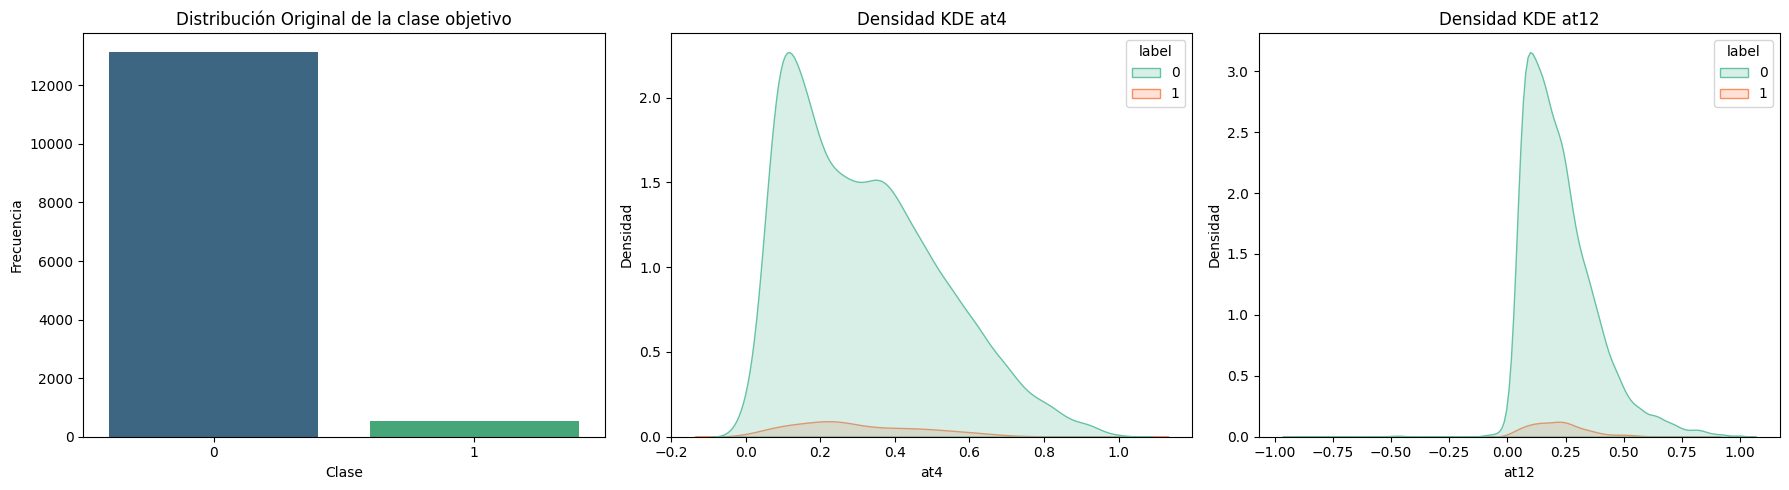

In [34]:
X = df.iloc[:, 1:-1]  # Atributos predictores (del 2 al 20)
y = df.iloc[:, -1]    # Etiqueta de clase (atributo 21)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

#se muestra el diagrama de barras de distribución de la clase objetivo
sns.countplot(x=y, ax=axes[0], palette="viridis")
axes[0].set_title("Distribución Original de la clase objetivo")
axes[0].set_xlabel("Clase")
axes[0].set_ylabel("Frecuencia")

#se muestra el diagrama de densidad para el atributo 5
attr_5_name = X.columns[4]  #el atributo 5 es la columna 4
sns.kdeplot(data=df, x=attr_5_name, hue=df.columns[-1], fill=True, ax=axes[1], palette="Set2")
axes[1].set_title(f"Densidad KDE {attr_5_name}")
axes[1].set_xlabel(f"{attr_5_name}")
axes[1].set_ylabel("Densidad")

#se muestra el diagrama de densidad para el atributo 13
attr_13_name = X.columns[12]  #el atributo 13 es la columna 12
sns.kdeplot(data=df, x=attr_13_name, hue=df.columns[-1], fill=True, ax=axes[2], palette="Set2")
axes[2].set_title(f"Densidad KDE {attr_13_name}")
axes[2].set_xlabel(f"{attr_13_name}")
axes[2].set_ylabel("Densidad")

plt.tight_layout()
plt.show()




In [35]:
#se muestran la cantidad de cada categoria de la variable objetivo
counts = y.value_counts()
perc = y.value_counts(normalize=True) * 100

#se imprimen los resultados
print(f"Análisis de Desbalance")
print(f"Clase 0 (Mayoritaria): {counts[0]} muestras ({perc[0]:.2f}%)")
print(f"Clase 1 (Minoritaria): {counts[1]} muestras ({perc[1]:.2f}%)\n")

Análisis de Desbalance
Clase 0 (Mayoritaria): 13137 muestras (96.19%)
Clase 1 (Minoritaria): 520 muestras (3.81%)



##Interpretación

Al imprimir la proporción de ambas clases, la mayoritaria que representa en valor 0, tiene un porcentaje de 96.19%, mientras que la clase con valor 1 o minoritaria presenta un porcentaje de 3.81%. La relacion es de 25:1. Este es un desbalance muy notorio por lo que el clasificador puede tener un accuracy elevado y favorecer a la clase mayoritaria.


##2. Modelo Base
Entrenar un modelo baseline utilizando:

Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
Este modelo deberá entrenarse sin aplicar métodos de tratamiento de desbalance y servirá como referencia para comparar los resultados posteriores.

Modelo entrenado: Modelo Base
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     13137
           1       1.00      0.01      0.02       520

    accuracy                           0.96     13657
   macro avg       0.98      0.50      0.50     13657
weighted avg       0.96      0.96      0.94     13657



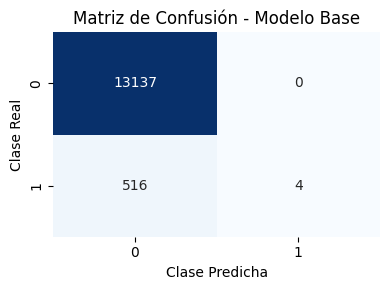

In [36]:
# Inicializamos la validación cruzada estratificada de 5 particiones
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#se crea una funcion para el calculo de prediciones y mostrar métricas
def evaluar_pipeline(pipeline, X, y, nombre_modelo):
    # cross_val_predict obtiene las predicciones de prueba limpias de data leakage
    y_pred = cross_val_predict(pipeline, X, y, cv=cv)

    #se calculan las métricas del modelo
    metrics = {
        'Accuracy': accuracy_score(y, y_pred),
        'Precision': precision_score(y, y_pred, zero_division=0),
        'Recall': recall_score(y, y_pred, zero_division=0),
        'F1-score': f1_score(y, y_pred, zero_division=0),
        'CM': confusion_matrix(y, y_pred)
    }

    print(f"Modelo entrenado: {nombre_modelo}")
    print(classification_report(y, y_pred, zero_division=0))


    #se grafica la matriz de Confusión
    plt.figure(figsize=(4, 3))
    sns.heatmap(metrics["CM"], annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"Matriz de Confusión - {nombre_modelo}")
    plt.ylabel("Clase Real")
    plt.xlabel("Clase Predicha")
    plt.tight_layout()
    plt.show()

    return metrics

resultados = {}

#se establece el pipeline base
pipeline_base = Pipeline([
    ('scaler', StandardScaler()), #se estandarizan los datos
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))  #se define a SVC como clasificador
])

#se llama la funcion previamente creada para evaluar
#y almacenar el modelo base con el pipeline
resultados['Baseline'] = evaluar_pipeline(pipeline_base, X, y, "Modelo Base")




##3. Tratamiento de clases no balanceadas
Aplicar y comparar los siguientes métodos:

SMOTEENN

One-Sided Selection


Para cada método:

Mostrar la nueva distribución de clases después del balanceo.

Entrenar nuevamente el modelo SVM utilizando los datos balanceados.

Modelo entrenado: Modelo con SMOTEENN
              precision    recall  f1-score   support

           0       0.99      0.81      0.89     13137
           1       0.14      0.80      0.25       520

    accuracy                           0.81     13657
   macro avg       0.57      0.81      0.57     13657
weighted avg       0.96      0.81      0.87     13657



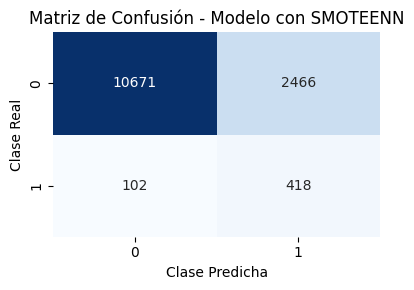

In [37]:
#se aplica SMOTEENN sobre con el pipeline de la librería imblearn
#se devine SVC como clasificador
pipeline_smoteenn = Pipeline([
    ('smoteenn', SMOTEENN(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
#se llama la funcion previamente creada para evaluar
#y almacenar el modelo SMOTEENN
resultados['SMOTEENN'] = evaluar_pipeline(pipeline_smoteenn, X, y, "Modelo con SMOTEENN")


Modelo entrenado: Modelo con One-Sided Selection
              precision    recall  f1-score   support

           0       0.96      1.00      0.98     13137
           1       1.00      0.01      0.02       520

    accuracy                           0.96     13657
   macro avg       0.98      0.50      0.50     13657
weighted avg       0.96      0.96      0.94     13657



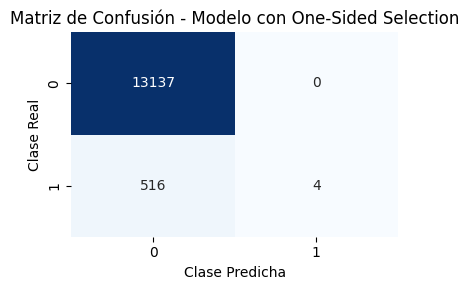

In [38]:
#se aplica el método One-Sided Selection con el pipeline de la librería de imblearn
#se define el SVC como clasificador
pipeline_oss = Pipeline([
    ('oss', OneSidedSelection(random_state=42)),
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale'))
])
#se llama la funcion previamente creada para evaluar
#y almacenar el modelo One-Sided Selection
resultados['OSS'] = evaluar_pipeline(pipeline_oss, X, y, "Modelo con One-Sided Selection")

##4. Entrenamiento y Evaluación del modelo

Utilizar validación cruzada estratificada de 5 particiones. (Se realizó en el inciso 2)

Implementar el flujo de trabajo utilizando Pipeline para evitar data leakage. (se usaron en el inciso 2 y 3 con el pipeline de imblearn)

Incorporar escalado de datos dentro del Pipeline. (se incluyó StandardScaler() dentro del pipeline)

Utilizar SVM con kernel RBF (se implementó dentro del pipeline para cada modelo entrenado)

In [39]:
#Nueva distribución de clases (Simulación explicativa post-balanceo)
print("Distribución de clases estimada despues del remuestreo")
X_s, y_s = SMOTEENN(random_state=42).fit_resample(X, y)
print(f"SMOTEENN Clase 0: {sum(y_s==0)} | Clase 1: {sum(y_s==1)}")
X_o, y_o = OneSidedSelection(random_state=42).fit_resample(X, y)
print(f"OSS      Clase 0: {sum(y_o==0)} | Clase 1: {sum(y_o==1)}\n")

Distribución de clases estimada despues del remuestreo
SMOTEENN Clase 0: 11888 | Clase 1: 13080
OSS      Clase 0: 12994 | Clase 1: 520



##5. Evaluación de resultados

Reportar y analizar al menos las siguientes métricas:

Accuracy

Precision

Recall

F1-score

Matriz de confusión

Además:

Comparar los resultados del modelo baseline contra los modelos balanceados.

Generar una gráfica comparativa de métricas.

Analizar si Accuracy es suficiente para evaluar el problema.

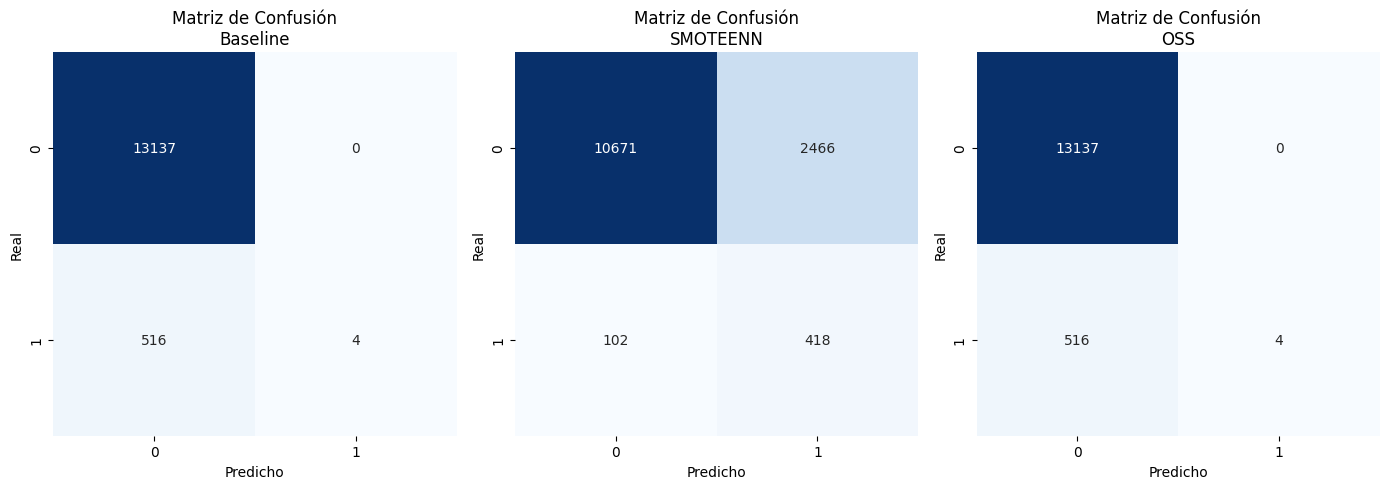

In [40]:
#se visualizan las matrices de Confusión en una gráfica
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for i, (nombre, res) in enumerate(resultados.items()):
    sns.heatmap(res['CM'], annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
    axes[i].set_title(f"Matriz de Confusión\n{nombre}")
    axes[i].set_xlabel("Predicho")
    axes[i].set_ylabel("Real")
plt.tight_layout()
plt.show()




#Interpretacion y Análisis de Matriz de Confusión
En la imagen, se aprecia la matriz de confusión para el modelo base, SMOTEENN y OSS. Estos dos ultimo se usaron porque como se vió al inicio, la variable objetivo presentaba un desbalance severo.

La matriz base, con SVM clasificó todos los casos reales de 0 (13137 valores). De la clase 1 (minoritaria), 516 casos se fallaron ya que eran 1 y se predijeron como 0 y sólo acertaron 4 casos como True Negative por lo que el modelo falla por el desbalance de clases.

Al aplicar SMOTEENN, que genera casos sistéticos de la clase minoritaria para compensar el desbalance, en la clase 0 los aciertos bajan a 10671, equivocándose en 2466 casos. Con la clase minoritaria, los valores mal clasificados como 0 disminuyen a 102 mientras que los valores bien clasificados como 0 aumenta a 418. Esto hace que el modelo sea mas equilibrado a la hora de detectar la clase minoritaria. Este proceso bajó la métrica precision mejorando la métrica recall.

En cambio, al aplicar One-Sided Selection, los resultados de la matriz de confusión fueron idénticos que al aplicar SVM en el modelo base. por lo que se concluye que no hay mejoría en el rebalanceo de clases con este método.

Se concluye que el método SMOTEENN es el mejor en este caso para rebalancear clases que están muy desbalanceadas.

##Gráfica comparativa de métricas

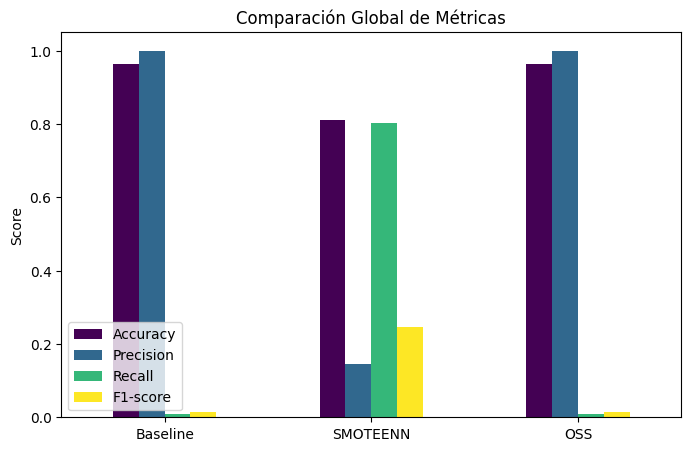

In [41]:
#se genera la gráfica con las métricas de accuracy, precision, recall y f1-score
df_metrics = pd.DataFrame(resultados).T.drop(columns=['CM'])

plt.figure(figsize=(8, 5))
df_metrics.plot(kind='bar', ax=plt.gca(), cmap='viridis')
plt.title("Comparación Global de Métricas")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc='lower left')
plt.show()

##6. Discusión y conclusiones
Discutir:

El impacto del desbalance sobre el desempeño del modelo.

Las diferencias observadas entre SMOTEENN y One-Sided Selection.

Qué método produjo los mejores resultados y por qué.

##Interpretación y análisis de demás métricas

Accuracy no es suficiente para determinar si el modelo tiene un buen rendimiento ya que en clases desbalanceadas, como este caso, la métrica puede mostrar valores muy altos prediciendo siempre la clase mayoritaria, pero cuando se trata de la clase minoritaria que es la de interés, el modelo falla.
Se recomienda en estos casos usar la métrica recall ya que sirve para medir la proporción de casos positivos reales e incluye ne su fórmula los falsos negativos que tuvieron que haber sido positivos pero el modelo los predijo erroneamente.

El impacto del desbalance en el desempeño del modelo es que éste pierde la capacidad para predecir sobre la clase minoritaria debido que el modelo aprendió en base a la clase mayoritaria.


Con el rebalanceo de clases, se sacrificó el accuracy para mejorar el recall lo cual nos ayudó a disminuir la cantidad de falsos positivos y que el modelo predijera mejor la clase minoritaria.

Los modelos baseline y OSS son los mismos por lo que el analisis de las métricas aplica para ambos. Estos presentan alta exactitud y precisión porque el modelo clasifica casi todo como si fuera clase mayoritaria. El recall y F1 score son nulos demostrando que ambos modelos son incapaces de detectar la clase minoritaria.

Referente a SMOTEENN, el accuracy y precision caen, pero esta ultima cae mucho mas lo que significa que el modelo comete mas errores al clasificar la clase mayoritaria. El recall sube gracias al rebalanceo haciendo que el modelo tenga mejor capacidad para detectar los casos reales de la clase minoritaria. Como consecuencia a este cambio entre precision y recall, F1 score tambien sube en este método.

La conclusiones son que cuando nos encontramos con clases muy desbalanceadas, hay que emplear métodos de rebalanceo para tratar de que el modelo predictivo mejore su capacidad para detectar la clase minoritaria que en la mayoría de casos, es la clase de interés. El método SMOTEENN fue mejor que el método OSS debido a que su capacidad para combinar el sobremuestreo  con el submuestreo le dió mejores resultados, mejorando las métricas en el modelo predictivo.
Finalmente, las diferencias entre SMOTEENN y OSS es que el primero tiene una capacidad de remuestreo híbrida generando muestras sintéticas de la clase minoritaria mediante SMOTE, y el segundo se basa en el submuestreo eliminando muestras redundantes de la clase mayoritaria y conservando intacta la minoritaria.